In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.calibration import calibration_curve

features = pd.read_pickle("../data/features_wc2018.pkl")

X = features[["distance", "angle"]]
y = features["goal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(1228, 2) (410, 2) 0.08224755700325732 0.08292682926829269


In [2]:
model = LogisticRegression()
model.fit(X_train, y_train)

test_probs = model.predict_proba(X_test)[:, 1]
print("Log loss:", log_loss(y_test, test_probs))
print("ROC AUC:", roc_auc_score(y_test, test_probs))

Log loss: 0.25133805393081926
ROC AUC: 0.7505475594493116


In [3]:
sb_probs = features.loc[X_test.index, "shot_statsbomb_xg"]
print("StatsBomb log loss:", log_loss(y_test, sb_probs))
print("StatsBomb ROC AUC:", roc_auc_score(y_test, sb_probs))

StatsBomb log loss: 0.2458232292780503
StatsBomb ROC AUC: 0.7712765957446809


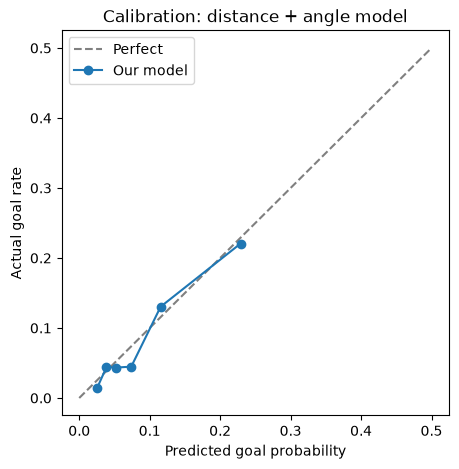

In [4]:
frac_pos, mean_pred = calibration_curve(y_test, test_probs, n_bins=6, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot([0, 0.5], [0, 0.5], "--", color="gray", label="Perfect")
plt.plot(mean_pred, frac_pos, marker="o", label="Our model")
plt.xlabel("Predicted goal probability")
plt.ylabel("Actual goal rate")
plt.legend()
plt.title("Calibration: distance + angle model")
plt.savefig("../figures/calibration_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import log_loss, roc_auc_score

features = pd.read_pickle("../data/features_wc2018.pkl")
y = features["goal"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Feature set 2: add header flag and shot type
X2 = features[["distance", "angle", "is_header"]].copy()
X2 = X2.join(pd.get_dummies(features["shot_type"], prefix="type").astype(int))

def evaluate(model, X, name):
    p = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    print(f"{name:35s} log loss {log_loss(y, p):.4f} | AUC {roc_auc_score(y, p):.4f}")
    return p

# No-skill reference: everyone gets the average goal rate
base_rate = np.full(len(y), y.mean())
print(f"{'Constant (no skill)':35s} log loss {log_loss(y, base_rate):.4f}")

evaluate(LogisticRegression(max_iter=1000), features[["distance", "angle"]], "Logistic: distance + angle")
evaluate(LogisticRegression(max_iter=1000), X2, "Logistic: + header + shot type")
evaluate(GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=42),
         X2, "Gradient boosting: all features")

sb = features["shot_statsbomb_xg"]
print(f"{'StatsBomb xG':35s} log loss {log_loss(y, sb):.4f} | AUC {roc_auc_score(y, sb):.4f}")

Constant (no skill)                 log loss 0.2846
Logistic: distance + angle          log loss 0.2535 | AUC 0.7360
Logistic: + header + shot type      log loss 0.2490 | AUC 0.7557
Gradient boosting: all features     log loss 0.2602 | AUC 0.7135
StatsBomb xG                        log loss 0.2373 | AUC 0.7815
